# Cardiovascular Disease Risk Factor Analysis

## Project Objective

The objective of this project is to explore relationships between cardiovascular disease prevalence and selected patient characterisitcs, including agee, physical activity, blood pressure, BMI, and cholesterol levels.

Using Python, pandas, and Matplotlib, this analysis examines patterns in cardiovascular disease prevalence across different patient groups. A basic logisitc regression model is also used to demonstrate how patient characterisitcs can be used to estimate the probability of cardivascular disease.

The analysis focuses on identifying associations rather than establising causation.

### Data Import and File Formatting

The original cardiovascular disease dataset was provided as a CSV file using semicolons (;) rather than commas to separate values.

To ensure the dataset was imported correctly, the sep=';' parameter was specified in the Pandas read_csv() function.

This allowed Pandas to recognize each variable as a separate column rather than interpreting the entire row as a single column.

In [1]:
import pandas as pd

df= pd.read_csv("cardio_train.csv", sep=";")

### 1. Dataset Overview and Initial Exploration

The dataset contains 70,000 patient records with information about cardiovascular disease status and several demographic, lifestyle, and health-related characteristics.

The variables include:
- Demographics: Age and gender.
- Physical measurements: Height and weight.
- Blood pressure: Stystolic and disastolic blood pressure.
- Health indicators: Cholesterol and glucose levels.
- Lifestlyle factors: Smoking, alcohol consumption, and physical activity.
- Target variable: cardio, where 0 indicates no cardiovascular disease and 1 indicates cardiovascular disease.

Initial Data Exploration

The initial exploration uses pandas to examine the dataset's structure, summary statistics, data types, and potential data quality issues.

The following methods are used:
- df.describe() to examine numerical distributions and identify potentially unrealistic values.
- df.info() to inspect column data types and non-null counts.

These initial checks help indentify issues that require further investigation before analysis.

In [2]:
df.describe()

,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
count,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000
mean,49972.419900,19468.865814,1.349571,164.359229,74.205690,128.817286,96.630414,1.366871,1.226457,0.088129,0.053771,0.803729,0.499700
std,28851.302323,2467.251667,0.476838,8.210126,14.395757,154.011419,188.472530,0.680250,0.572270,0.283484,0.225568,0.397179,0.500003
min,0.000000,10798.000000,1.000000,55.000000,10.000000,-150.000000,-70.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,25006.750000,17664.000000,1.000000,159.000000,65.000000,120.000000,80.000000,1.000000,1.000000,0.000000,0.000000,1.000000,0.000000
50%,50001.500000,19703.000000,1.000000,165.000000,72.000000,120.000000,80.000000,1.000000,1.000000,0.000000,0.000000,1.000000,0.000000
75%,74889.250000,21327.000000,2.000000,170.000000,82.000000,140.000000,90.000000,2.000000,1.000000,0.000000,0.000000,1.000000,1.000000
max,99999.000000,23713.000000,2.000000,250.000000,200.000000,16020.000000,11000.000000,3.000000,3.000000,1.000000,1.000000,1.000000,1.000000


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 70000 entries, 0 to 69999
Data columns (total 13 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           70000 non-null  int64  
 1   age          70000 non-null  int64  
 2   gender       70000 non-null  int64  
 3   height       70000 non-null  int64  
 4   weight       70000 non-null  float64
 5   ap_hi        70000 non-null  int64  
 6   ap_lo        70000 non-null  int64  
 7   cholesterol  70000 non-null  int64  
 8   gluc         70000 non-null  int64  
 9   smoke        70000 non-null  int64  
 10  alco         70000 non-null  int64  
 11  active       70000 non-null  int64  
 12  cardio       70000 non-null  int64  
dtypes: float64(1), int64(12)
memory usage: 6.9 MB


### Initial Dataset  Inspection

Preview the original dataset to understand its structure, availble variables, and recorded values before data cleaning.

In [4]:
df.head(10)

,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,0,18393,2,168,62.0,110,80,1,1,0,0,1,0
1,1,20228,1,156,85.0,140,90,3,1,0,0,1,1
2,2,18857,1,165,64.0,130,70,3,1,0,0,0,1
3,3,17623,2,169,82.0,150,100,1,1,0,0,1,1
4,4,17474,1,156,56.0,100,60,1,1,0,0,0,0
5,8,21914,1,151,67.0,120,80,2,2,0,0,0,0
6,9,22113,1,157,93.0,130,80,3,1,0,0,1,0
7,12,22584,2,178,95.0,130,90,3,3,0,0,1,1
8,13,17668,1,158,71.0,110,70,1,1,0,0,1,0
9,14,19834,1,164,68.0,110,60,1,1,0,0,0,0


In [5]:
df['age_years'] = (df['age'] / 365.25).round(1)

### Data Quality Checks

Check for missing values and examine the number of unique values in each column to understand the dataset and identify potential quality issues.

**Finding:** No missing values were indentified in the original dataset.

In [6]:
df.isnull().sum()

id             0
age            0
gender         0
height         0
weight         0
ap_hi          0
ap_lo          0
cholesterol    0
gluc           0
smoke          0
alco           0
active         0
cardio         0
age_years      0
dtype: int64

In [7]:
df.nunique()

id             70000
age             8076
gender             2
height           109
weight           287
ap_hi            153
ap_lo            157
cholesterol        3
gluc               3
smoke              2
alco               2
active             2
cardio             2
age_years        263
dtype: int64

### Data Cleaning and Variable Transformation

Created a working copy of the original dataset to preserve the raw data. Converted age from days to years, weight from kilograms to pounds, and height from centimeters to inches to improve interpretability.

Removed the original measurement columns after conversion and previewed the updated dataset to verify transformations.

In [8]:
df_clean= df.copy()

In [9]:
df_clean= df_clean.drop(columns=['age'])

In [10]:
df_clean['weight_lbs'] = (df_clean['weight'] * 2.20462).round(1)

In [11]:
df_clean['height_inches'] = (df_clean['height'] / 2.54).round(1)

In [12]:
df_clean= df_clean.drop(columns= ['height', 'weight'])

In [13]:
df_clean.head(10)

,id,gender,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio,age_years,weight_lbs,height_inches
0,0,2,110,80,1,1,0,0,1,0,50.4,136.7,66.1
1,1,1,140,90,3,1,0,0,1,1,55.4,187.4,61.4
2,2,1,130,70,3,1,0,0,0,1,51.6,141.1,65.0
3,3,2,150,100,1,1,0,0,1,1,48.2,180.8,66.5
4,4,1,100,60,1,1,0,0,0,0,47.8,123.5,61.4
5,8,1,120,80,2,2,0,0,0,0,60.0,147.7,59.4
6,9,1,130,80,3,1,0,0,1,0,60.5,205.0,61.8
7,12,2,130,90,3,3,0,0,1,1,61.8,209.4,70.1
8,13,1,110,70,1,1,0,0,1,0,48.4,156.5,62.2
9,14,1,110,60,1,1,0,0,0,0,54.3,149.9,64.6


### Descriptive Statistics and Outlier Investigation

Examine the distribution of numerical variables using summary statistics, including the mean, standard deviation, quartiles, and minimum and maximum values.

This initial review helps identify potentially unrealistic measurements, particularly in blood pressure, height, and weight, that require further investigation before analysis.

In [14]:
df_clean.describe()

,id,gender,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio,age_years,weight_lbs,height_inches
count,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.00000,70000.000000
mean,49972.419900,1.349571,128.817286,96.630414,1.366871,1.226457,0.088129,0.053771,0.803729,0.499700,53.302913,163.59472,64.706780
std,28851.302323,0.476838,154.011419,188.472530,0.680250,0.572270,0.283484,0.225568,0.397179,0.500003,6.755126,31.73697,3.232138
min,0.000000,1.000000,-150.000000,-70.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,29.600000,22.00000,21.700000
25%,25006.750000,1.000000,120.000000,80.000000,1.000000,1.000000,0.000000,0.000000,1.000000,0.000000,48.400000,143.30000,62.600000
50%,50001.500000,1.000000,120.000000,80.000000,1.000000,1.000000,0.000000,0.000000,1.000000,0.000000,53.900000,158.70000,65.000000
75%,74889.250000,2.000000,140.000000,90.000000,2.000000,1.000000,0.000000,0.000000,1.000000,1.000000,58.400000,180.80000,66.900000
max,99999.000000,2.000000,16020.000000,11000.000000,3.000000,3.000000,1.000000,1.000000,1.000000,1.000000,64.900000,440.90000,98.400000


### Blood Pressure Outlier Investigation

Initial descriptive statistics revealed unrealistic blood pressure measurements, including negative values and extremely high systolic and diastolic readings.

Further investigation identified 953 records with diastolic blood pressure above 200mmHg. Several abnormal values occured repeatedly, suggesting possible data-entry or measurement errors.

These observations require additional cleaning before cardiovascular disease analysis.

In [15]:
df_clean[df_clean['ap_lo'] > 200].sort_values(by='ap_lo', ascending=False)[['ap_hi', 'ap_lo']]

print("Records with diastolic BP above 200:",
      (df_clean['ap_lo'] > 200).sum())

Records with diastolic BP above 200: 953


In [16]:
df_clean.loc[df_clean['ap_lo'] > 200, 'ap_lo'].value_counts().head(50)

ap_lo
1000     666
1100     156
1200      21
1110      11
1001       8
800        5
1120       5
1008       4
10000      3
8099       3
809        3
8000       2
902        2
1033       2
1088       2
709        2
1011       2
9011       2
708        2
850        2
5700       2
1177       2
900        2
1400       2
1900       2
801        2
710        2
1003       2
8044       1
9100       1
1077       1
8500       1
7100       1
1007       1
1022       1
1044       1
2088       1
802        1
8079       1
1111       1
1002       1
810        1
7099       1
11000      1
1125       1
8100       1
8200       1
9800       1
820        1
1139       1
Name: count, dtype: int64

In [17]:
df_clean= df_clean.rename(columns= {'ap_hi' : 'ap_hi_sys', 'ap_lo' : 'ap_lo_dia'})

In [18]:
df_clean['ap_lo_dia'].sort_values().head(20)

60106   -70
17381     0
2014      0
38370     0
63787     0
22923     0
31783     0
48049     0
42397     0
43922     0
45835     0
27686     0
41505     0
23867     0
65303     0
40330     0
13489     0
16459     0
25454     0
56950     0
Name: ap_lo_dia, dtype: int64

In [19]:
df_clean.loc[df_clean['ap_lo_dia'] < 40, ['ap_hi_sys', 'ap_lo_dia']].sort_values(by='ap_lo_dia')

print("Records with diastolic BP below 40:",
      (df_clean['ap_lo_dia'] < 40).sum())

Records with diastolic BP below 40: 59


In [20]:
df_clean.loc[(df_clean['ap_hi_sys'] < 70) | (df_clean['ap_hi_sys'] > 250), ['ap_hi_sys', 'ap_lo_dia']
    ].sort_values(by='ap_hi_sys')

,ap_hi_sys,ap_lo_dia
35040,-150,80
23988,-140,90
25240,-120,80
46627,-120,80
16021,-115,70
...,...,...
46912,14020,90
47253,14020,90
25519,14020,80
25464,14020,80


### Blood Pressure Validation

Following the initial investigation of blood pressure outliers, records were flagged using predefined systolic and diastolic thresholds.

A total of 1,329 records were flagged for further review. Of these, 1,258 records met the criteria for clearly invalid blood pressure measurements, including nonpositive values or systolic pressure less than or equal to diastolic pressure.

The remaining flagged records were examined separately before determining the final cleaning criteria.

In [21]:
bp_flagged = df_clean[
    (df_clean['ap_hi_sys'] < 70) | 
    (df_clean['ap_hi_sys'] > 250) |
    (df_clean['ap_lo_dia'] < 40) |
    (df_clean['ap_lo_dia'] > 200) |
    (df_clean['ap_hi_sys'] <= df_clean['ap_lo_dia'])
    ]
     

len(bp_flagged)

1329

In [22]:
# Identify clearly invalid blood pressure records:
# 1. Systolic pressure <= 0
# 2. Diastolic pressure <= 0
# 3. Systolic pressure <= diastolic pressure


bp_invalid = df_clean[
    (df_clean['ap_hi_sys'] <= 0) |
    (df_clean['ap_lo_dia'] <= 0) |
    (df_clean['ap_hi_sys'] <= df_clean['ap_lo_dia'])
]
len(bp_invalid)

1258

In [23]:
bp_remaining = bp_flagged[~bp_flagged.index.isin(bp_invalid.index)]

bp_remaining[['ap_hi_sys', 'ap_lo_dia']]

,ap_hi_sys,ap_lo_dia
418,150,30
1876,902,60
4817,909,60
5333,120,30
6737,150,10
...,...,...
63996,1205,90
64911,906,60
68223,130,20
68568,110,6


### Blood Pressure Cleaning

After investigating abnormal blood pressure measurements, 1,329 flagged records were removed using the established systolic and diastolic thresholds.

The dataset was reduced from 70,000 to 68,671 observations. A subsequent validation confirmed that no remaining records violated these thresholds.

In [24]:
df_bp_clean= df_clean.drop(index=bp_flagged.index)

len(df_bp_clean)

68671

In [25]:
len(df_bp_clean[
    (df_bp_clean['ap_hi_sys'] < 70) | 
    (df_bp_clean['ap_hi_sys'] > 250) |
    (df_bp_clean['ap_lo_dia'] < 40) |
    (df_bp_clean['ap_lo_dia'] > 200) |
    (df_bp_clean['ap_hi_sys'] <= df_bp_clean['ap_lo_dia'])])

0

### Height and Weight Outlier Investigation

Following blood pressure cleaning, height and weight measurements were examined using descriptive statistics to identify potentially unrealistic values.

Initial results revealed height ranging from 21.7 to 98.4 inches and weights ranging from 24.3 to 440.0 pounds.

Extreme measurements were investigated further before deciding which observations to exclude.

In [26]:
df_bp_clean[['height_inches', 'weight_lbs']].describe()

,height_inches,weight_lbs
count,68671.00000,68671.000000
mean,64.70747,163.401682
std,3.22172,31.595493
min,21.70000,24.300000
25%,62.60000,143.300000
50%,65.00000,158.700000
75%,66.90000,180.800000
max,98.40000,440.900000


In [27]:
df_bp_clean['height_inches'].value_counts().sort_index(ascending=False).head(20)

height_inches
98.4      1
81.5      1
78.0     14
77.6      4
77.2      6
76.8      6
76.4      2
76.0      6
75.6     12
75.2     11
74.8     40
74.4     36
74.0     45
73.6     75
73.2    102
72.8    225
72.4    150
72.0    155
71.7    321
71.3    188
Name: count, dtype: int64

#### Investigation of Extreme Height and Weight Measurements

Further examination identified a single patient with a recorded height of 98.4 inches. This observation was excluded as a likely data-entry-error, reducing the dataset to 68,670 records.

Two patient weighing 440.9 pounds were also indentified. Their recorded heights were 73.2 and 70.9 inches. Although unusually high, these weights were retained because they are physiologically possible.

Additional investigation focused on patients with recorded heights of 48 inches or less, examining their age and weight to determine whether these observations required exclusion.

In [28]:
df_bp_clean.loc[df_bp_clean['height_inches']==98.4, ['height_inches', 'weight_lbs', 'age_years', 'gender']]

,height_inches,weight_lbs,age_years,gender
6486,98.4,189.6,58.1,1


In [29]:
df_bp_clean = df_bp_clean[df_bp_clean['height_inches'] !=98.4]

In [30]:
df_bp_clean.loc[df_bp_clean['weight_lbs'] ==440.9, ['height_inches', 'weight_lbs', 'age_years', 'gender']]

,height_inches,weight_lbs,age_years,gender
435,73.2,440.9,45.9,1
50413,70.9,440.9,41.4,2


In [31]:
df_bp_clean.loc[df_bp_clean['height_inches'] <=48, ['height_inches', 'weight_lbs', 'age_years', 'gender']
    ].sort_values(by='height_inches')

,height_inches,weight_lbs,age_years,gender
22723,21.7,178.6,64.0,1
66643,22.4,134.5,51.6,1
64115,23.2,127.0,50.4,1
29157,23.6,152.1,52.3,1
27603,25.2,134.5,57.4,1
...,...,...,...,...
61602,47.2,176.4,50.2,2
13952,47.2,176.4,39.5,2
11183,47.2,176.4,60.5,1
3735,47.2,154.3,48.3,1


### Height and Weight Data Cleaning

Following the removal of invalid blood pressure records, height and weight measurements were examined for potentially unrealistic values.

Initial exploration identified 83 patients with recorded heights of 48 inches or less. Given the adult age range of the dataset and the associated weight measurements, these records were excluded as likely measurement or data entry errors.

The remaining records were then examined for unusually low body weights. Body Mass Index (BMI) was calculated to assess weight relative to height and identify additional extreme observations.

In [32]:
df_height_clean= df_bp_clean[df_bp_clean['height_inches'] > 48]

In [33]:
low_weight= df_height_clean[df_height_clean['weight_lbs'] < 87
    ].copy()

low_weight['BMI'] = (
    low_weight['weight_lbs'] * 703 / 
    (low_weight['height_inches'] ** 2)
    ).round(1)

low_weight[
    ['age_years', 'height_inches', 'weight_lbs', 'BMI']
    ].sort_values(by='BMI')

,age_years,height_inches,weight_lbs,BMI
33817,59.1,70.1,24.3,3.5
29488,55.9,69.7,48.5,7.0
60188,59.8,63.8,46.3,8.0
26806,63.7,61.8,50.7,9.3
60699,51.7,67.3,63.9,9.9
16906,47.3,66.9,68.3,10.7
18559,49.7,63.0,66.1,11.7
58200,61.7,66.5,77.2,12.3
16322,59.9,65.0,77.2,12.8
38417,59.7,60.6,70.5,13.5


In [34]:
pd.cut(
    low_weight['BMI'],
    bins=[0, 10, 12, 14, 16, 18.5, 25],
    right=False
).value_counts().sort_index()

BMI
[0.0, 10.0)      5
[10.0, 12.0)     2
[12.0, 14.0)     3
[14.0, 16.0)    12
[16.0, 18.5)    22
[18.5, 25.0)     4
Name: count, dtype: int64

In [35]:
low_weight.loc[
    low_weight['BMI'] < 14,
    ['age_years', 'height_inches', 'weight_lbs', 'BMI', 'cardio']
    ].sort_values(by='BMI')

,age_years,height_inches,weight_lbs,BMI,cardio
33817,59.1,70.1,24.3,3.5,1
29488,55.9,69.7,48.5,7.0,0
60188,59.8,63.8,46.3,8.0,1
26806,63.7,61.8,50.7,9.3,0
60699,51.7,67.3,63.9,9.9,1
16906,47.3,66.9,68.3,10.7,1
18559,49.7,63.0,66.1,11.7,1
58200,61.7,66.5,77.2,12.3,1
16322,59.9,65.0,77.2,12.8,0
38417,59.7,60.6,70.5,13.5,0


### BMI Outlier Removal

#### BMI was calculated using height in inches and weight in pounds.

An examination of low-weight patients identified several extremely low BMI values, including measurements below 10.

Records with BMI below 14 were excluded to reduce the influence of potentially erroneous measurements. BMI was then recalculated for the remaining observations.

One additional record with a BMI of 106.9 was excluded as an extreme observation.

Following these cleaning steps, the final dataset contained 68,576 patient records.

In [36]:
df_weight_clean= df_height_clean.drop(
    index=low_weight[low_weight['BMI'] < 14].index
)

len(df_weight_clean)

68577

In [37]:
df_weight_clean['BMI'] = (
    df_weight_clean['weight_lbs'] * 703 / 
    (df_weight_clean['height_inches'] ** 2)
).round(1)

In [38]:
df_bmi_clean= df_weight_clean[
    df_weight_clean['BMI'] != 106.9
    ].copy()

len(df_bmi_clean)

68576

### Categorical Variable Validation

Following the removal of invalid and extreme measurements, the categorical variables were examined to verify their recorded values and distributions.

Frequency counts were generated for gender, cholesterol, glucose, smoking, alcohol consumption, physical activity, and cardiovascular disease status.

This step helps identify unexpected category values and confirms the distribution of the categorical features before beginning the analysis.

In [39]:
columns = [
    'gender', 'cholesterol', 'gluc', 'smoke', 'alco', 'active', 'cardio']

for col in columns:
    print(col)
    print(df_bmi_clean[col].value_counts().sort_index())
    print()

gender
gender
1    44668
2    23908
Name: count, dtype: int64

cholesterol
cholesterol
1    51422
2     9292
3     7862
Name: count, dtype: int64

gluc
gluc
1    58303
2     5062
3     5211
Name: count, dtype: int64

smoke
smoke
0    62542
1     6034
Name: count, dtype: int64

alco
alco
0    64916
1     3660
Name: count, dtype: int64

active
active
0    13481
1    55095
Name: count, dtype: int64

cardio
cardio
0    34650
1    33926
Name: count, dtype: int64



### Impact of Data Cleaning on Cardiovascular Disease Distribution

The proportion of patients with and without cardiovascular disease was compared between the original and cleaned datasets to assess whether the cleaning process substantially changed the outcome distribution.

##### Results:
| Cardiovascular Disease Status | Original Dataset | Cleaned Dataset |
|---|---|---|
| No cardiovascular disease (0) | 50.03% | 50.53% |
| Cardiovascular disease (1) | 49.97% | 49.47% |

The proportion of patients with cardiovascular disease decreased by approximately 0.50 percentage points following cleaning.

The overall outcome distribution remained nearly balanced, suggesting that the cleaning process did not substantially alter the proportion of positive and negative cardiovascular disease cases.


In [40]:
print("original dataset:")
print(df['cardio'].value_counts(normalize=True) * 100)

print("cleaned dataset:")
print(df_bmi_clean['cardio'].value_counts(normalize=True) * 100)

original dataset:
cardio
0    50.03
1    49.97
Name: proportion, dtype: float64
cleaned dataset:
cardio
0    50.527881
1    49.472119
Name: proportion, dtype: float64


## Question 1: How Does Cardiovascular Disease Prevalence Vary Across Age Groups, and How Does Physical Activity Relate to That Prevalence?

#### Age Group Analysis

Patients were divided into age groups to examine how cardiovascular disease prevalence changes with age.

For each age group, the total number of patients and the percentage diagnosed with cardiovascular disease were calculated.

This analysis provides an initial understanding of the relationship between age and cardiovascular disease before examining differences in physical activity.

In [41]:
df_bmi_clean['age_group'] = pd.cut(
    df_bmi_clean['age_years'],
    bins=[25, 35, 40, 45, 50, 55, 60, 65],
    labels=['25-34', '35-39', '40-44', '45-49', '50-54', '55-59', '60-64'],
    right=False
)

In [42]:
age_prevalence= (
    df_bmi_clean.groupby('age_group', observed=True)['cardio']
    .agg(['count', 'mean'])
)

age_prevalence['prevalence_pct'] = (age_prevalence['mean'] * 100).round(2)

age_prevalence

,count,mean,prevalence_pct
age_group,,,
25-34,4,0.000000,0.00
35-39,1676,0.242243,24.22
40-44,8404,0.303070,30.31
45-49,10850,0.428111,42.81
50-54,17070,0.458407,45.84
55-59,17760,0.560529,56.05
60-64,12812,0.667187,66.72


#### Initial Findings: Age and Cardiovascular Disease

Cardiovascular disease prevalence increased across successive age groups, rising from 24.22% among patients aged 35-39 to 66.72% among patients aged 60-64.

The 25-34 age group contained only four patients and was therefore considered insufficient for meaningful interpretation.

These findings indicate a strong positive association between age and cardiovascular disease prevalence in this dataset. However, the results are observational and do not establish causation.

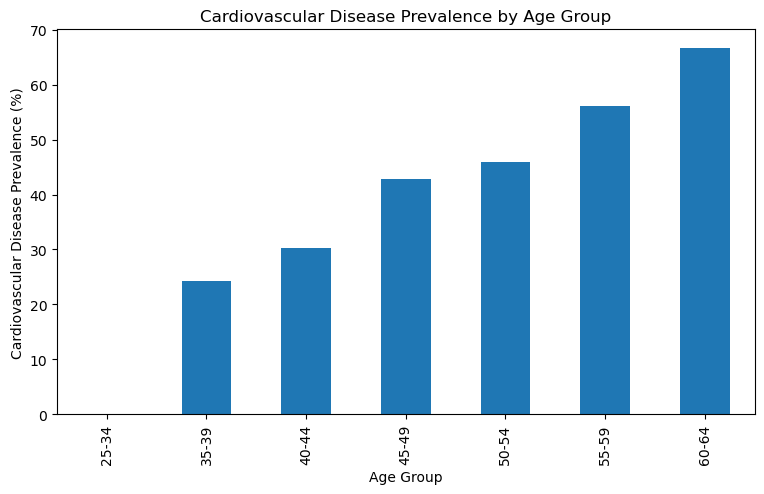

In [43]:
ax= age_prevalence['prevalence_pct'].plot(
kind='bar',
figsize=(9,5),
title='Cardiovascular Disease Prevalence by Age Group'
)

ax.set_xlabel('Age Group')
ax.set_ylabel('Cardiovascular Disease Prevalence (%)');

In [44]:
activity_prevalence = (df_bmi_clean.groupby(['age_group', 'active'], observed=True)['cardio']
                       .agg(['count', 'mean'])
                      )

activity_prevalence['prevalence_pct']= (activity_prevalence['mean'] * 100).round(2)

activity_prevalence

count      mean  prevalence_pct
age_group active                                 
25-34     1           4  0.000000            0.00
35-39     0         328  0.274390           27.44
          1        1348  0.234421           23.44
40-44     0        1603  0.317530           31.75
          1        6801  0.299662           29.97
45-49     0        2042  0.472576           47.26
          1        8808  0.417802           41.78
50-54     0        3416  0.493560           49.36
          1       13654  0.449612           44.96
55-59     0        3471  0.600691           60.07
          1       14289  0.550773           55.08
60-64     0        2621  0.704311           70.43
          1       10191  0.657639           65.76

#### Question 1 - Key Findings

Cardiovascular disease prevalence increased across the age groups analyzed, rising from 24.22% among patients aged 35-39 to 65.72% among those aged 60-64.

Physical activity was associated with lower cardiovascular disease prevalence within the age groups with adequate sample sizes. For example, among patients aged 45-49, prevalence was 47.26% for inactive patients compared with 41.78% for active patients.

Limitation: The 25-34 age group contained only four patients, making it unsuitable for meaningful comparison. These findings describe associations rather than casual relationships.

## Question 2 - Does elevated blood pressure correspond to higher cardiovascular disease prevalence, and does that relationship differ by age?


##### Method: Patients were grouped into four blood pressure categories using systolic (ap_hi_sys) and diastolic (ap_lo_dia) readings: Normal, Elevated, Stage 1, and Stage 2.

##### Cardiovascular disease prevalence will be compared across these categories and age groups.

In [45]:
import numpy as np

conditions= [
    (df_bmi_clean['ap_hi_sys'] < 120) &
    (df_bmi_clean['ap_lo_dia'] < 80),

    (df_bmi_clean['ap_hi_sys'] < 130) &
    (df_bmi_clean['ap_lo_dia'] < 80), 

    (df_bmi_clean['ap_hi_sys'] < 140) &
    (df_bmi_clean['ap_lo_dia'] < 90)
    ]

categories = [ 'Normal', 'Elevated', 'Stage 1']

df_bmi_clean['bp_category'] = np.select(conditions, categories, default='Stage 2')

In [46]:
df_bmi_clean['bp_category'].value_counts()

bp_category
Stage 1     32415
Stage 2     23519
Normal       9538
Elevated     3104
Name: count, dtype: int64

In [47]:
df_bmi_clean[(df_bmi_clean['ap_hi_sys'] >= 120) &
    (df_bmi_clean['ap_hi_sys'] < 130) &
    (df_bmi_clean['ap_lo_dia'] < 80)
    ][['ap_hi_sys', 'ap_lo_dia']].shape

(3104, 2)

In [48]:
bp_prevalence = (
    df_bmi_clean.groupby('bp_category')['cardio']
    .agg(['count', 'mean'])
)

bp_prevalence['prevalence_pct'] = (bp_prevalence['mean'] * 100
                                  ).round(2)

bp_prevalence = bp_prevalence.reindex(['Normal', 'Elevated', 'Stage 1', 'Stage 2'])


bp_prevalence

,count,mean,prevalence_pct
bp_category,,,
Normal,9538,0.221325,22.13
Elevated,3104,0.323131,32.31
Stage 1,32415,0.384513,38.45
Stage 2,23519,0.780135,78.01


In [49]:
bp_age_prevalence = (df_bmi_clean.groupby(
    ['age_group', 'bp_category'],
    observed=True)['cardio']
      .agg(['count', 'mean'])
)



bp_age_prevalence['prevalence_pct'] = (bp_age_prevalence['mean'] * 100).round(2)


bp_age_prevalence

count      mean  prevalence_pct
age_group bp_category                                 
25-34     Normal           2  0.000000            0.00
          Stage 1          2  0.000000            0.00
35-39     Elevated        89  0.179775           17.98
          Normal         498  0.086345            8.63
          Stage 1        761  0.145861           14.59
          Stage 2        328  0.719512           71.95
40-44     Elevated       453  0.136865           13.69
          Normal        2063  0.113912           11.39
          Stage 1       4062  0.215903           21.59
          Stage 2       1826  0.751917           75.19
45-49     Elevated       522  0.270115           27.01
          Normal        1984  0.185988           18.60
          Stage 1       5069  0.311501           31.15
          Stage 2       3275  0.780458           78.05
50-54     Elevated       767  0.267275           26.73
          Normal        2262  0.217949           21.79
          Stage 1       8477  0.341394           34.14
          Stage 2       5564  0.760784           76.08
55-59     Elevated       791  0.429836           42.98
          Normal        1740  0.309195           30.92
          Stage 1       8394  0.447105           44.71
          Stage 2       6835  0.778932           77.89
60-64     Elevated       482  0.495851           49.59
          Normal         989  0.437816           43.78
          Stage 1       5650  0.575221           57.52
          Stage 2       5691  0.812862           81.29

In [50]:
bp_age_prevalence = bp_age_prevalence.reindex(['Normal', 'Elevated', 'Stage 1', 'Stage 2'],
                                              level='bp_category')
bp_age_prevalence


count      mean  prevalence_pct
age_group bp_category                                 
25-34     Normal           2  0.000000            0.00
          Stage 1          2  0.000000            0.00
35-39     Normal         498  0.086345            8.63
          Elevated        89  0.179775           17.98
          Stage 1        761  0.145861           14.59
          Stage 2        328  0.719512           71.95
40-44     Normal        2063  0.113912           11.39
          Elevated       453  0.136865           13.69
          Stage 1       4062  0.215903           21.59
          Stage 2       1826  0.751917           75.19
45-49     Normal        1984  0.185988           18.60
          Elevated       522  0.270115           27.01
          Stage 1       5069  0.311501           31.15
          Stage 2       3275  0.780458           78.05
50-54     Normal        2262  0.217949           21.79
          Elevated       767  0.267275           26.73
          Stage 1       8477  0.341394           34.14
          Stage 2       5564  0.760784           76.08
55-59     Normal        1740  0.309195           30.92
          Elevated       791  0.429836           42.98
          Stage 1       8394  0.447105           44.71
          Stage 2       6835  0.778932           77.89
60-64     Normal         989  0.437816           43.78
          Elevated       482  0.495851           49.59
          Stage 1       5650  0.575221           57.52
          Stage 2       5691  0.812862           81.29

#### Question 2 - Key Findings

##### Overall Blood Pressure Analysis

Cardiovascular disease prevalence increased across the four blood pressure categories:
- Normal: 22.13%
- Elevated: 32.31%
- Stage 1: 38.45%
- Stage 2: 78.01%

Patients classified as Stage 2 had the highest cardivascular disease prevalence, exceeding the Normal category by 55.88 percentage points.

Age-Stratified Analysis

Comparing blood pressure categories within individual age groups generally showed higher cardiovascular disease prevalence among patients with more elevated blood pressure.

One exception occurred among patients aged 35-39, where the Elevated category had a prevalence of 17.98$ (89 patients), compared with 14.59% for Stage 1 (761 patients). The smaller Elevated sample may contribute to this difference.

#### Interpretation

These findings suggest a strong association between higher blood pressure categories and cardiovascular disease prevalence. However, this observational analysis cannot establish causation.

## Question 3: Is BMI or Cholesterol More Strongly Associated With Cardiovascular Disease After Accounting for Age?

#### Objective

This analysis investigates the relationship between Body Mass Index (BMI), cholesterol levels, and cardiovascular disease prevalence.

The goal is to determine whether higher BMI and cholesterol levels are associated with increased cardiovascular disease prevalence and whether these relationships remain after accounting for age.

#### Methodology 
- Categorize patients by BMI using standard BMI classifications: Underweight, Normal, Overweight, and Obese.
- Calculate cardiovascular disease prevalence within each BMI category.
- Calculate cardiovascular disease prevalence across the three cholesterol levels.
- Compare both relationships across age groups to examine potential age-related differences.
- Use logistic regression to evaluate the associations of BMI and cholesterol with cardiovascular disease while controlling for age.

In [51]:
df_bmi_clean['bmi_category'] = pd.cut(
    df_bmi_clean['BMI'],
    bins=[0, 18.5, 25, 30, float('inf')],
    labels=['Underweight', 'Normal', 'Overweight', 'Obese'],
    right=False
)

df_bmi_clean['bmi_category'].value_counts().sort_index()

bmi_category
Underweight      612
Normal         25149
Overweight     24772
Obese          18043
Name: count, dtype: int64

In [52]:
bmi_prevalence = (
    df_bmi_clean.groupby('bmi_category', observed= True)['cardio']
    .agg(['count', 'mean'])
)

bmi_prevalence['prevalence_pct'] = (
    bmi_prevalence['mean'] * 100
    ).round(2)

bmi_prevalence

,count,mean,prevalence_pct
bmi_category,,,
Underweight,612,0.274510,27.45
Normal,25149,0.396914,39.69
Overweight,24772,0.505046,50.50
Obese,18043,0.624342,62.43


### BMI and Cardiovascular Disease Prevalence

#### Key Findings

Cardiovascular disease prevalence increased progressively across the BMI categories:
- Underweight: 27.45% (612 patients)
- Normal: 39.69% (25,149 patients)
- Overweight: 50.50% (24,772 patients)
- Obese: 62.43% (18,043 patients)

Patients classified as obese had the highest cardiovascular disease prevalence, approximately 22.74 percentage points higher than patients in the normal BMI category.

#### Interpretation 

These findings indicate a positive association between BMI category and cardiovascular disease prevalence. As BMI categories increase, the proportion of patients with cardiovascular disease also increases.

However, these comparisons do not account for difference in age or cholesterol levels. Further analysis is necessary to determine whether the association remains after accounting for these variables.

In [53]:
chol_prevalence = (
    df_bmi_clean.groupby('cholesterol')['cardio'].agg(['count', 'mean'])
)
chol_prevalence['prevalence_pct'] = (
    chol_prevalence['mean'] * 100).round(2)

chol_prevalence

,count,mean,prevalence_pct
cholesterol,,,
1,51422,0.435417,43.54
2,9292,0.596427,59.64
3,7862,0.762401,76.24


### Cholesterol Levels and Cardiovascular Disease Prevalence

#### Key Findings

Cardiovascular disease prevalence increased across the three cholesterol categories:
- Level 1 (Normal): 43.54% (51,422 patients)
- Level 2 (Above Normal): 59.64% (9,292 patients)
- Level 3 (Well Above Normal): 76.24% (7,862 patients)

Patients with Level 3 cholesterol had the highest cardiovascular disease prevalence, approximately 32.70 percentage points higher than patients with normal cholesterol levels.

#### Interpretation

These findings indicate a positive association between cholesterol levels and cardiovascular disease prevalence.

The increase in prevalence across cholesterol categories suggests that elevated cholesterol may be an important indicator of cardiovascular disease.

However, these results do not account for differences in patient age or BMI. Additional analysis is needed to evaluate whether this relationship persists after accounting for these factors.

In [54]:
bmi_age = (df_bmi_clean.groupby(['age_group', 'bmi_category'],
                                observed=True
                               )['cardio'].agg(['count', 'mean'])
          )

bmi_age['prevalence_pct'] = (bmi_age['mean'] * 100).round(2)

bmi_age

count      mean  prevalence_pct
age_group bmi_category                                 
25-34     Normal            3  0.000000            0.00
          Obese             1  0.000000            0.00
35-39     Underweight      32  0.062500            6.25
          Normal          760  0.167105           16.71
          Overweight      551  0.263158           26.32
          Obese           333  0.396396           39.64
40-44     Underweight     126  0.103175           10.32
          Normal         3770  0.223077           22.31
          Overweight     2835  0.330511           33.05
          Obese          1673  0.451883           45.19
45-49     Underweight     116  0.241379           24.14
          Normal         4200  0.333571           33.36
          Overweight     3915  0.439591           43.96
          Obese          2619  0.570829           57.08
50-54     Underweight     125  0.224000           22.40
          Normal         6388  0.363964           36.40
          Overweight     6293  0.467504           46.75
          Obese          4264  0.593340           59.33
55-59     Underweight     124  0.443548           44.35
          Normal         5889  0.478349           47.83
          Overweight     6506  0.555641           55.56
          Obese          5241  0.661706           66.17
60-64     Underweight      89  0.471910           47.19
          Normal         4139  0.597004           59.70
          Overweight     4672  0.674443           67.44
          Obese          3912  0.737219           73.72

In [55]:
chol_age = (df_bmi_clean.groupby(['age_group', 'cholesterol'],
                                observed=True
                               )['cardio'].agg(['count', 'mean'])
          )

chol_age['prevalence_pct'] = (chol_age['mean'] * 100).round(2)

chol_age

count      mean  prevalence_pct
age_group cholesterol                                 
25-34     1                4  0.000000            0.00
35-39     1             1424  0.198736           19.87
          2              195  0.456410           45.64
          3               57  0.596491           59.65
40-44     1             7047  0.257131           25.71
          2              979  0.486210           48.62
          3              378  0.685185           68.52
45-49     1             8617  0.374840           37.48
          2             1468  0.573569           57.36
          3              765  0.749020           74.90
50-54     1            13091  0.407608           40.76
          2             2331  0.555127           55.51
          3             1648  0.725121           72.51
55-59     1            12599  0.508136           50.81
          2             2506  0.616919           61.69
          3             2655  0.755932           75.59
60-64     1             8640  0.616551           61.66
          2             1813  0.714286           71.43
          3             2359  0.816448           81.64

### Age-Stratified Analysis: BMI and Cholesterol

#### Key Findings

To investigate the influence of age, cardiovascular disease prevalence was compared across BMI and cholesterol categories within individual age groups.

#### BMI Findings
- Cardiovascular disease prevalence generally increased from Normal to Overweight to Obese BMI categories within the age groups examined.
- For patients aged 40-44, prevalence increased from 22.31% among patientswith normal BMI to 33.05% among overweight patients and 45.19% among obese patients.
- The 25-34 age group contained only four patients, making it too small for meaningful interpretation.

#### Cholesterol Findings
- Cardiovascular disease prevalence also increased across cholesterol categories within the age groups examined.
- Among patients aged 40-44, prevalence increased from 25.71% for normal cholesterol to 48.62% for above-normal cholesterol and 68.52% for well-above-normal cholesterol.
- This pattern suggests that the association between cholesterol and cardiovascular disease is not explained soley by difference in age.

#### Interpretation

Both BMI and cholesterol demonstrated positive associations with cardiovascular disease prevalence when patients were grouped by age.

These findings suggest that both variables may contribute useful information beyond age alone. However, age-stratified comparisons do not simultaneously account for BMI and cholesterol.

Logisitc regression will therefore be used to examine their associations with cardiovascular disease while controlling for age and for each other.

### Logistic Regression: Adjusting for Age, BMI, and Cholesterol

#### Objective

To determine whether BMI or cholesterol has a stronger association with cardivascular disease after account for age.

#### Methodology

Logistic regression was selected because cardiovascular disease status (cardio) is a binary variable:
- 0 = No cardiovascular disease
- 1 = Cardiovascular disease present

The model includes three explanatory variables:
- Age: Measured in years.
- BMI Category: Underweight, Normal, Overweight, and Obese.
- Cholesterol: Normal(1), Above Normal(2), and Well Above Normal(3).

Categorical variables were converted into dummy variables to make them suitable for logistic regression.

Underweight BMI and normal cholesterol (level 1) were used as reference categories.

The model estimates the association of each variable with cardiovascular disease while holding the other included variables constant.

In [56]:
X= df_bmi_clean[['age_years', 'bmi_category', 'cholesterol']]

Y= df_bmi_clean['cardio']

X.head()

,age_years,bmi_category,cholesterol
0,50.4,Normal,1
1,55.4,Obese,3
2,51.6,Normal,3
3,48.2,Overweight,1
4,47.8,Normal,1


### Preparing Categorical Variables for Logistic Regression

BMI categories and cholesterol levels were converted into dummy variables using pd.get_dummies().

Each dummy variable represents a category using binary values (0 or 1).

The drop_first=True parameter was used to establish reference categories and avoid including redundant variables in the regression model.

- BMI reference category: Underweight
- Cholesterol reference category: Normal(Level 1)

All patients remain in the dataset. The reference categories are excluded only as separate predictor columns.

This allows the regression coefficients to represent differences relative to their repsective reference categories.

In [57]:
X_encoded = pd.get_dummies(
    X,
    columns=['bmi_category', 'cholesterol'],
    drop_first=True,
    dtype=int
)

X_encoded.head()

,age_years,bmi_category_Normal,bmi_category_Overweight,bmi_category_Obese,cholesterol_2,cholesterol_3
0,50.4,1,0,0,0,0
1,55.4,0,0,1,0,1
2,51.6,1,0,0,0,1
3,48.2,0,1,0,0,0
4,47.8,1,0,0,0,0


### Logistic Regression Model

A logistic regression model was fitted to examine the association between BMI category, cholesterol level, age, and cardivascular disease.

The dependent variable was cardio, where 0 represents the absence of cardiovascular disease and 1 represents its presence.

The model included 68,576 observations and used age, BMI category, and cholesterol level as explanatory variables.

Unlike linear regression, logistic regression is apporpriate for a binary outcome. The model estimates how each explanatory variable is associated with the odds of cardiovascular disease while accounting for the other included variables.

The statsmodels library was used to obtain regression coefficients, statistical significance tests, and model fit statistics.

In [58]:
import statsmodels.api as sm

X_sm = sm.add_constant(X_encoded)

logit_model = sm.Logit(Y, X_sm).fit()

print(logit_model.summary())

Optimization terminated successfully.
         Current function value: 0.635198
         Iterations 5
                           Logit Regression Results                           
Dep. Variable:                 cardio   No. Observations:                68576
Model:                          Logit   Df Residuals:                    68569
Method:                           MLE   Df Model:                            6
Date:                Thu, 19 Nov 2026   Pseudo R-squ.:                 0.08353
Time:                        17:08:18   Log-Likelihood:                -43559.
converged:                       True   LL-Null:                       -47529.
Covariance Type:            nonrobust   LLR p-value:                     0.000
                              coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------
const                      -4.4948      0.115    -39.210      0.000      -4.719   

#### Logistic Regression - Key Findings

The logistic regression model included 68,576 observations and successfully converged. The model examined the relationship between age, BMI category, cholesterol level, and cardiovascular disease.

#### Key Findings
- Age: Each additional year of age was associated with approximately 6.7% higher odds of cardiovascular disease, after accounting for BMI and cholesterol.
- BMI: Compared with Underweight patients, Normal BMI patients had approximately 1.64 times the odds of cardiovascular disease, Overweight patients had 2.34 times the odds, and Obese patients had 3.42 times the odds, after accounting for age and cholesterol.
- Cholesterol: Compared with patients with Normal cholesterol (Level 1), patients with Above Normal cholesterol (Level 2) had approximately 1.72 times the odds of cardiovascular disease, while patients with Well Above Normal cholesterol (Level 3) had approximately 3.16 times the odds, after accounting for age and BMI.
- Statistical Significance: All included predictors had statistically significant coefficients (p < 0.001).
- Model Fit: The model's McFadden pseudo R-squared was approximately 0.0835, indicating improvement in model fit compared with an intercept only model. This should not be interpreted as the percentage of cardiovascular disease outcomes explained.

#### Model Interpretation

Age, BMI category, and cholesterol level were positively associated with cardiovascular disease in this model.

The odds ratios demonstrate how the odds of cardiovascular disease differ across categories while accounting for the other included variables.

However, odds ratios are not direct changes in probability, and these observational findings do not establish causation.

Additionally, the Underweight reference category contanined only 612 patients, considerably fewer than the othr BMI categories, so those comparisons should be interpreted cautiously.

### Model Comparison - BMI vs. Cholesterol 

To determine whether BMI or cholesterol contributes more information to the logistic regression model, two additional models were fitted:
- Model without BMI: Includes age and cholesterol/
- Model without cholesterol: Includes age and BMI

Each reduced model was compared with the original model containing all three explanatory variables.

The change in log-likelihood was calcualted to measure how much model fit deteriorated when each variable was removed.

A larger loss in log-likelihood indicates that removing the variable has a greater negative impact on model fit, suggesting that the variable contributes more information to the full model.

In [59]:
X_no_bmi = X_sm.drop(
    columns= [col for col in X_sm.columns
              if col.startswith('bmi_category_')]
)
model_no_bmi = sm.Logit(Y, X_no_bmi).fit()

X_no_chol = X_sm.drop(
    columns=[col for col in X_sm.columns
             if col.startswith('cholesterol_')]
)
model_no_chol = sm.Logit(Y, X_no_chol).fit()

comparison= pd.DataFrame({
    'Variable Removed': ['BMI', 'Cholesterol'],
    'Loss_in_Log_Likelihood': [
        logit_model.llf - model_no_bmi.llf,
        logit_model.llf - model_no_chol.llf
    ]
})
comparison

Optimization terminated successfully.
         Current function value: 0.644847
         Iterations 5
Optimization terminated successfully.
         Current function value: 0.650223
         Iterations 5


,Variable Removed,Loss_in_Log_Likelihood
0,BMI,661.686194
1,Cholesterol,1030.320254


### Model Comparison and Likelihood Ratio Tests - Key Findings

To evaluate the contributions of BMI and cholesterol, two reduced logistic regression models were compared against the full model containing age, BMI category, and cholesterol level.

#### Key Findings:
- Removing BMI: The model's log-likelihood decreased by approximately 661.69. The likelihood ratio test produced a statistic of 1,323.37 (df=3, p < 0.001), indicating that BMI significantly improved model fit.
- Removing Cholesterol: The model's log-likelihood decreased by approximately 1,030.32. The likelihood ratio test produced a statistic of 2,060.64 (df=2, p < 0.001), indicating that cholesterol significantly improved model fit.

#### Interpretation:

Both BMI and cholesterol contributed statistically significant information to the model after accounting for age and the other predictor.

Removing cholesterol resulted in a larger deterioration in model fit than removing BMI, suggesting that cholesterol provided greater incremental explanatory information within this model specification.

However, these comparisons do not establish causation or prove that cholesterol is universally a stronger predictor than BMI.

In [60]:
from scipy.stats import chi2

lr_bmi = 2 * (logit_model.llf - model_no_bmi.llf)
lr_chol = 2 * (logit_model.llf - model_no_chol.llf)

df_bmi = logit_model.df_model - model_no_bmi.df_model
df_chol = logit_model.df_model - model_no_chol.df_model

p_bmi = chi2.sf(lr_bmi, df_bmi)
p_chol = chi2.sf(lr_chol, df_chol)

lr_results = pd.DataFrame({
    'Variable': ['BMI', 'Cholesterol'],
    'LR Statistic': [lr_bmi, lr_chol],
    'Degrees of Freedom': [df_bmi, df_chol],
    'P Value': [p_bmi, p_chol]
})

lr_results

,Variable,LR Statistic,Degrees of Freedom,P Value
0,BMI,1323.372388,3.0,1.248665e-286
1,Cholesterol,2060.640508,2.0,0.000000e+00


#### Logistic Regression - Hypothetical Patient Prediction

To demonstrate how the logistic regression model can be applied, a hypothetical patient was created with the following characteristics:
- Age: 55 years
- BMI Category: Obese
- Cholesterol Level: 3(Well Above Normal)

The patient's characteristics were encoded using the same predictor columns as the original regression model.

The fitted model was then used to estimate the proability of cardiovascular disease for this combination of characteristics.

In [61]:
patient= pd.DataFrame(
    0,
    index=[0],
    columns=X_sm.columns
)

patient['const'] = 1
patient['age_years'] = 55
patient['bmi_category_Obese'] = 1 
patient['cholesterol_3'] = 1

probability = logit_model.predict(patient).iloc[0]

print(f"Predicted probability: {probability:.2%}")

Predicted probability: 81.16%


#### Hypothetical Prediction - Interpretation

Using the logistic regression model, a hypothetical 55-year-old patient classified as Obese with Well Above Normal cholesterol (Level 3) received an estimated cardivascular disease probability of 81.16%.

This indicates that, based on the relationships identified in the dataset, the model estimates an 81.16% probability that a patient with these characteristics belong to the cardiovascular disease group.

##### Important Considerations:

- This prediction reflects the statistical relationships learned from the dataset and should not be interpreted as a clinical diagnosis.
- The model estimates the probability of existing cardiovascular disease status, not the probability of developing cardiovascular disease in the future.
- Because the model was no evaluated on a separate test dataset, its predictive accuracy and generalizability have not been established.


##### Conclusion:  
This example demonstrates how logistic regression can translate patient characteristics into an estimated probability while highlighting the importance of model validation before real-world application.

### Data Visualizations - Summary of Findings

The following visualizations summarize the relationships identified across the three research questions. Bar charts were created using Matplotlib to compare cardiovascular disease prevalence across age groups, physical activity status, blood pressure categories, BMI categories, and cholesterol levels.

#### Cardiovascular Disease Prevalence by Age and Physical Activity

Cardiovascular disease prevalence was calculated for each age group and physical activity status.

Patients were grouped by age_group and active, where:
- 0: Physically inactive
- 1: Physically active

The mean of the binary cardio variable was multiplied by 100 to calculate disease prevalence as a percentage.

The 25-34 age group was excluded from the visualization because it contained only four observations, making meaningful comparisons unreliable.


In [62]:
import pandas as pd
import matplotlib.pyplot as plt

age_activity = (
    df_bmi_clean
    .groupby(['age_group', 'active'], observed=True)['cardio']
    .agg(['mean', 'count'])
    .reset_index()
)

age_activity['prevalence_pct'] = (
    age_activity['mean'] * 100
)

age_activity


,age_group,active,mean,count,prevalence_pct
0,25-34,1,0.000000,4,0.000000
1,35-39,0,0.274390,328,27.439024
2,35-39,1,0.234421,1348,23.442136
3,40-44,0,0.317530,1603,31.752963
4,40-44,1,0.299662,6801,29.966181
5,45-49,0,0.472576,2042,47.257591
6,45-49,1,0.417802,8808,41.780200
7,50-54,0,0.493560,3416,49.355972
8,50-54,1,0.449612,13654,44.961184
9,55-59,0,0.600691,3471,60.069144


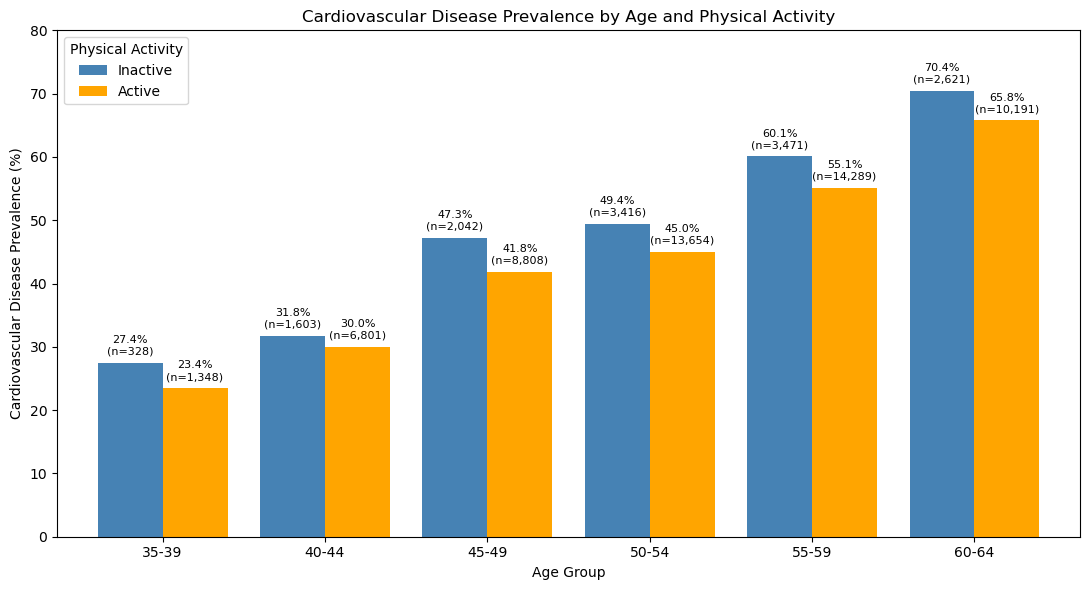

In [63]:
plot_data = age_activity[
    age_activity['age_group'] != '25-34'
    ]

chart_data = plot_data.pivot(
    index='age_group',
    columns= 'active',
    values='prevalence_pct'
)

ax= chart_data.plot(
    kind='bar',
    figsize=(11,6),
    width=0.8,
    color=['steelblue', 'orange']
)


count_data= plot_data.pivot(
    index='age_group',
    columns='active',
    values='count'
)

count_data = count_data.reindex(
    index=chart_data.index,
    columns= chart_data.columns
)

for bars, activity in zip(ax.containers, chart_data.columns): 
    for bar, n in zip(bars, count_data[activity]):
        height = bar.get_height()

        ax.text(
            bar.get_x() + bar.get_width() / 2,
            height + 1,
            f'{height:.1f}%\n(n={int(n):,})',
            ha='center',
            va='bottom',
            fontsize=8
        )

plt.title('Cardiovascular Disease Prevalence by Age and Physical Activity')
plt.xlabel('Age Group')
plt.ylabel('Cardiovascular Disease Prevalence (%)')
plt.xticks(rotation=0)
plt.legend(['Inactive', 'Active'], title= 'Physical Activity')
plt.ylim(0, 80)

plt.tight_layout()
plt.show()

#### Visualization - Key Findings

Cardiovascular disease prevalence generally increased across older age groups, regardless of physical activity status.

Within every displayed age group, physcially active patients had lower cardiovascular disease prevalence than inactive patients.

For example, among patients aged 35-39, prevalence was approximately 27.4% for inactive patients compared with 23.4% for active patients.

These findings suggest an association between physical activity and lower cardivascular disease prevalence. However, they do not establish that physical activity directly caused the observed difference.

### Cardiovascular Disease Prevalence by Blood Pressure Category

Cardiovascular disease prevalence was caluclated across four blood pressure categories: Normal, Elevated, Stage 1, and Stage 2.

Patients were grouped by bp_category, and the mean of the binary cardio variable was multiplied by 100 to calculate prevalence as a percentage.

A bar chart was created to visualize how cardiovascular disease prevalence differs across blood pressure categories.

In [64]:
bp_summary = (
    df_bmi_clean
    .groupby('bp_category', observed=True)['cardio']
    .agg(['mean', 'count'])
    .reset_index()
)

bp_summary['prevalence_pct'] = (
    bp_summary['mean'] * 100
)

bp_summary

,bp_category,mean,count,prevalence_pct
0,Elevated,0.323131,3104,32.313144
1,Normal,0.221325,9538,22.132523
2,Stage 1,0.384513,32415,38.451334
3,Stage 2,0.780135,23519,78.013521


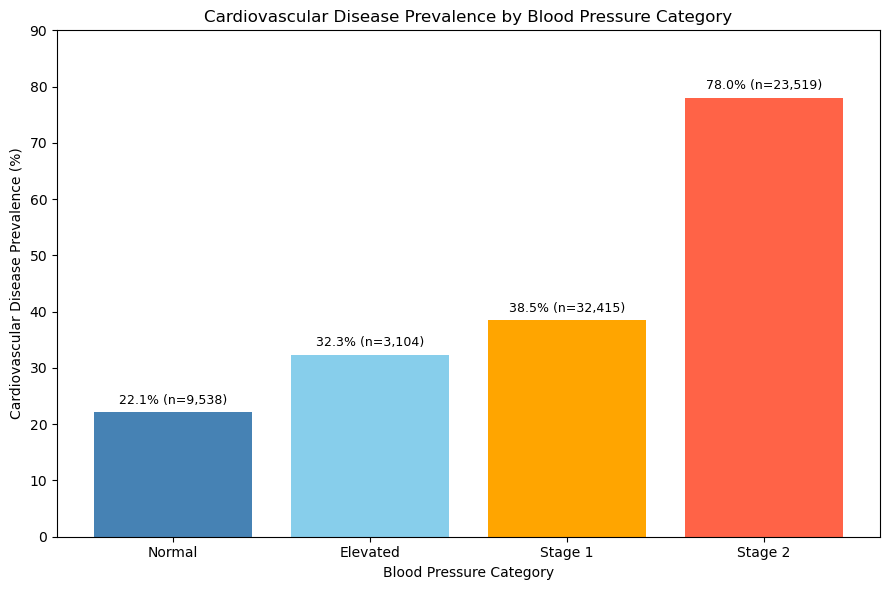

In [65]:
bp_order = ['Normal', 'Elevated', 'Stage 1', 'Stage 2']

bp_plot = (
    bp_summary
    .set_index('bp_category')
    .loc[bp_order]
)

plt.figure(figsize=(9,6))

bars= plt.bar(
    bp_plot.index,
    bp_plot['prevalence_pct'],
    color=['steelblue', 'skyblue', 'orange', 'tomato']
)

sample_sizes = (
    df_bmi_clean['bp_category']
    .value_counts()
    .reindex(bp_plot.index)
)

for bar, n in zip(bars, sample_sizes):
    height= bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 1,
        f'{height:.1f}% (n={n:,})',
        ha = 'center',
        va = 'bottom',
        fontsize=9
    )

plt.title('Cardiovascular Disease Prevalence by Blood Pressure Category')
plt.xlabel('Blood Pressure Category')
plt.ylabel('Cardiovascular Disease Prevalence (%)')
plt.ylim(0, 90)

plt.tight_layout()
plt.show()

#### Blood Pressure Visualizations - Key Findings

Cardiovascular disease prevalence increased across progressively higher blood pressure categories.
- Normal: 22.1%
- Elevated: 32.3%
- Stage 1: 38.5%
- Stage 2: 78.0%

The largest increase occured between Stage 1 and Stage 2, where cardiovascular disease prevalence increased by approximately 39.6 percentage points.

Stage 2 patients demonstrated substantially higher cardiovascular disease prevalence than patients in the other blood pressure categories.

These findings support an association between elevated blood pressure and cardiovascular disease. However, this visualization does not establish causation or adjust for other patient characteristics.


### Cardiovascular Disease Prevalence by BMI and Cholesterol

To further examine the relationships between BMI, cholesterol, and cardiovascular disease, prevalence was calculated separately for each BMI and cholesterol category.

Patients were grouped into four BMI categories (Underweight, Normal, Overweight, and Obese) and three cholesterol categories (Normal, Above Normal, and Well Above Normal).

For each category, the analysis calculated:
- Mean: The proportion of patients with cardivascular disease.
- Count: The total number of patients in the category.
- Prevalence (%): The mean multiplied by 100.

These summary tables provide the data used to create the BMI and cholesterol visualizations.

The comparisons are unadjusted; the earlier logistic regression analysis was used to account for age and other included predictor.

In [66]:
bmi_summary = (
    df_bmi_clean
    .groupby('bmi_category', observed=True)['cardio']
    .agg(['mean', 'count'])
    .reset_index()
)

bmi_summary['prevalence_pct'] = (
    bmi_summary['mean'] * 100
)

chol_summary = (
    df_bmi_clean
    .groupby('cholesterol')['cardio']
    .agg(['mean', 'count'])
    .reset_index()
)

chol_summary['prevalence_pct'] = (
    chol_summary['mean'] * 100
)

display(bmi_summary)
display(chol_summary)

,bmi_category,mean,count,prevalence_pct
0,Underweight,0.274510,612,27.450980
1,Normal,0.396914,25149,39.691439
2,Overweight,0.505046,24772,50.504602
3,Obese,0.624342,18043,62.434185


,cholesterol,mean,count,prevalence_pct
0,1,0.435417,51422,43.541675
1,2,0.596427,9292,59.642703
2,3,0.762401,7862,76.240142


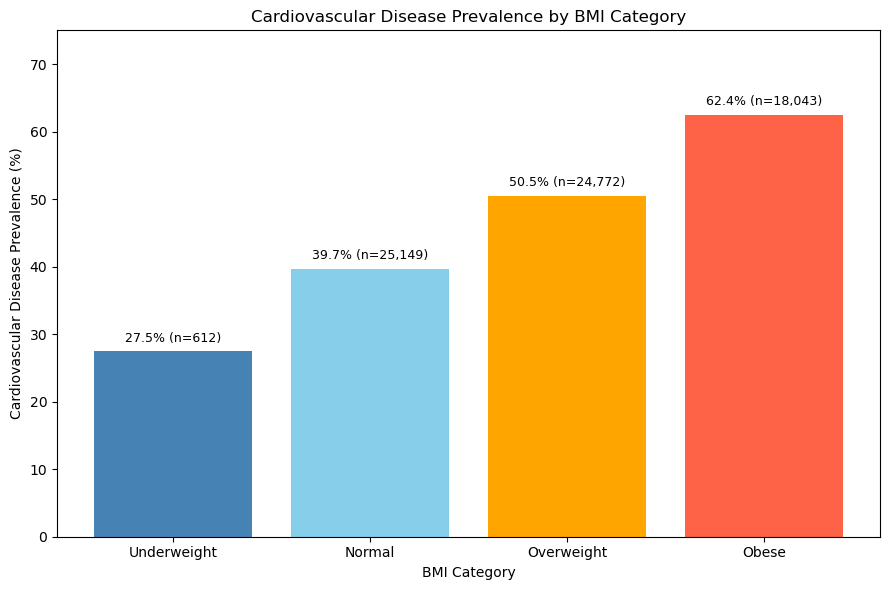

In [67]:
plt.figure(figsize=(9, 6))

bars= plt.bar(
    bmi_summary['bmi_category'].astype(str),
    bmi_summary['prevalence_pct'],
    color=['steelblue', 'skyblue', 'orange', 'tomato']
)

sample_sizes = [612, 25149, 24772, 18043]

for bar, n in zip(bars, sample_sizes):
    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 1,
        f'{height:.1f}% (n={n:,})',
        ha= 'center',
        va= 'bottom',
        fontsize=9
    )



plt.title('Cardiovascular Disease Prevalence by BMI Category')
plt.xlabel('BMI Category')
plt.ylabel('Cardiovascular Disease Prevalence (%)')
plt.ylim(0, 75)

plt.tight_layout()
plt.show()

#### BMI Visualization - Key Findings

The bar chart illustrates a consistent increase in cardiovascular disease prevalence across higher BMI categories. Prevalence ranged from 27.5% among Underweight patients (n=612) to 62.4% among Obese patients (n=18,043). However, the substantially smaller Underweight sample should be considered when interpreting this comparison.

#### Interpretation:

The results demonstrate a positive association between BMI category and cardiovascular disease prevalence. Patients in higher BMI categories were more likely to have cardiovascular disease in this dataset.

However, these percentage are unadjusted and do not account for differences in age or cholesterol levels between BMI groups. The logistic regression analysis provides an adjusted comparison.

Additionally, the Underweight category contains considerably fewer patients (612) than the other BMI categories, so its results should be interpreted with greater caution.

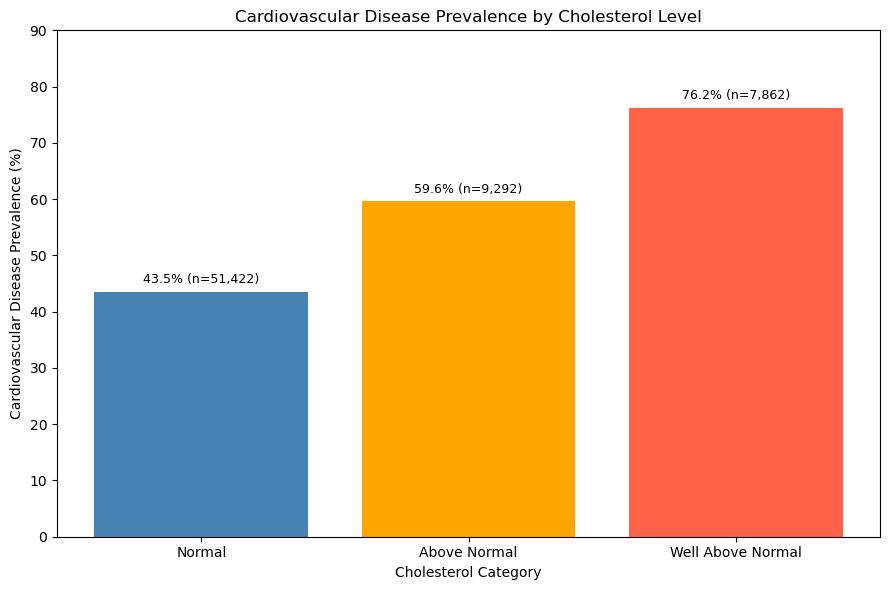

In [68]:
plt.figure(figsize=(9, 6))

bars = plt.bar(
    ['Normal', 'Above Normal', 'Well Above Normal'],
    chol_summary['prevalence_pct'],
    color=['steelblue', 'orange', 'tomato']
)

sample_sizes = chol_summary['count']

for bar, n in zip(bars, sample_sizes):
    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 1,
        f'{height:.1f}% (n={n:,})',
        ha= 'center',
        va= 'bottom',
        fontsize=9
    )

plt.title('Cardiovascular Disease Prevalence by Cholesterol Level')
plt.xlabel('Cholesterol Category')
plt.ylabel('Cardiovascular Disease Prevalence (%)')
plt.ylim(0, 90)

plt.tight_layout()
plt.show()

#### Cholesterol Visualization - Key Findings

The bar chart demonstrates a consistent increase in cardiovascular disease prevalence across higher cholesterol categories. Patients with Normal cholesterol had a cardiovascular disease prevalence of 43.5% (n=51,422), compared with 59.6% (n=9,292) for Above Normal cholesterol and 76.2% (n=7,862) for Well Above Normal cholesterol.

The difference between the Normal and Well Above Normal categories was approximately 32.7 percentage points, indicating a substantial association between elevated cholesterol and cardiovascular disease prevalence.

#### Interpretation:

The results indicate a strong positive association between elevated cholesterol levels and cardiovascular disease prevalence.

Patients with the highest cholesterol category had substantially higher disease prevalence than those with normal cholesterol.

These results are unadjusted and do not account for differences in age or BMI between cholesterol groups.

The logistic regression analysis provides further evidence by evaluating cholesterol and BMI while accounting for age. In that model, removing cholesterol produced a greater reduction in model fit than removing BMI, suggesting cholesterol contributed more explanatory information within the selected model.

Limitation: These findings demonstrate an association, not a casual relationship between cholesterol and cardiovascular disease.

## Project Conclusion

This project analyzed 68,576 patient records to investigate how age, physical activity, blood pressure, BMI, and cholesterol levels relate to cardiovascular disease prevalence.

#### Key Findings.

1. Age and Physical Activity

Cardiovascular disease prevalence generally increased across older age groups. Within the age groups examined, physically active patients consistently demonstrated lower cardiovascular disease prevalence than inactive patients.

2. Blood Pressure

Cardiovascular disease prevalence increased across higher blood pressure categories, from 22.1% among patients with Normal blood pressure to 78.0% among patients classified as Stage 2 hypertension.

3. BMI and Cholesterol

Higher BMI categories and elevated cholesterol levels were both associated with increased cardiovascular disease prevalence. Logistic regression confirmed that both variables remained statistically significant after accounting or age and the other included predictor.

Model comparison tests indicated that removing cholesterol caused a greater deterioration in model fit than removing BMI, suggesting that cholesterol contributed more incremental explanatory information within this model.

### Overall Conclusion

The analysis identified meaningful associations between cardiovascular disease and several patient characteristics, particularly age, blood pressure, BMI, and cholesterol.

The project demonstrates how explanatory data analysis, data visualization, and logistic regression can be combined to investigate relationships within healthcare data.

Because the analysis used observational data, these findings should not be interpreted as casual relationships or clinically validated predictions.

## Project Limitations and Future Improvements

#### Limitations

Although this analysis identified several associations with cardiovascular disease, certain limitations should be considered.

1. Observational Data

The dataset contains patient characteristics and cardiovascular disease status. Therefore, the relationships identified represent statistical associations rather than evidence of causation.

2. Uneven Sample Sizes

Some patient categories contained considerably fewer observations than others. FOr example, the 25-34 age group contained only four patients, while the Underweight BMI category contained 612 patients.

Results from smaller groups may be less reliable and should be interpreted cautiously.

3. Data Quality and Cleaning

The original dataset contained unrealistic blood pressure, height, and weight measurements that required cleaning.

Removing these observations improved data quality but may have introduced selection bias if excluded records differed systematically from retained patients.

4. Limited Regression Variables

The logistic regression model included age, BMI category, and cholesterol level.

Other potentially relevant factors, including physical activity, smoking, glucose levels, and blood pressure, were not included in this particular model.

5. Model Validation

The logistic regression analysis was conducted using the cleeaned dataset without a separate training and testing evaluation.

Although the model identified statistically significant associations, its predictive accuracy and ability to generalize to new patients were not evaluated.

### Future Improvements

#### Future analysis could expand on this project by:

- Including additional explanatory variables such as blood pressure, smoking status, physical activity, and glucose levels.
- Evaluating the logistic regression model using separate training and testing datasets.
- Measuring predictive performance using accuracy, precision, recall, and ROC-AUC.
- Investigating whether the relationships between cardiovascular disease and individual risk factors differ across age groups.
- Exploring potential interactions between BMI, cholesterol, and blood pressure.

These improvements could provide a more comprehensive understanding of cardiovascular disease patterns and strengthen the reliability of future predictive models.